<div style=" background-color: RGB(0,114,200);" >
<h1 style="margin: auto; padding: 20px 0; color:#fff; text-align: center">PROJET 4 DATA ANALYST</h1>
<h2 style="margin: auto; padding: 20px 0; color:#fff; text-align: center">Réalisez une étude de santé publique avec R ou Python
</h2>
</div>

<div style="background-color: RGB(0,150,250);" >
<h2 style="margin: auto; padding: 20px; color:#fff; ">Etape 1 - Importation des librairies et chargement des fichiers</h2>
</div>

<div style="border: 1px solid RGB(0,150,250);" >
<h3 style="margin: auto; padding: 20px; color: RGB(0,150,250); ">1.1 - Importation des librairies</h3>
</div>

In [ ]:
#Importation de la librairie Pandas
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

<div style="border: 1px solid RGB(0,150,250);" >
<h3 style="margin: auto; padding: 20px; color: RGB(0,150,250); ">1.2 - Chargement des fichiers Excel</h3>
</div>

In [ ]:
#Importation du fichier population.csv
population = pd.read_csv('population.csv')

#Importation du fichier dispo_alimentaire.csv
dispo_alimentaire = pd.read_csv('dispo_alimentaire.csv')

#Importation du fichier aide_alimentaire.csv
aide_alimentaire = pd.read_csv('aide_alimentaire.csv')

#Importation du fichier sous_nutrition.csv
sous_nutrition = pd.read_csv('sous_nutrition.csv')

<div style="background-color: RGB(0,150,250);" >
<h2 style="margin: auto; padding: 20px; color:#fff; ">Etape 2 - Analyse exploratoire des fichiers</h2>
</div>

<div style="border: 1px solid RGB(0,150,250);" >
<h3 style="margin: auto; padding: 20px; color: RGB(0,150,250); ">2.1 - Analyse exploratoire du fichier population</h3>
</div>

In [ ]:
#Afficher les dimensions du dataset
print("Le tableau comporte {} observation(s) ou article(s)".format(population.shape[0]))
print("Le tableau comporte {} colonne(s)".format(population.shape[1]))

Le tableau comporte 1416 observation(s) ou article(s)
Le tableau comporte 3 colonne(s)


In [ ]:
.3#Consulter le nombre de colonnes
'Nombre de colonnes:', len(population.columns)

#La nature des données dans chacune des colonnes
print(population.dtypes)

#Le nombre de valeurs présentes dans chacune des colonnes


population.info()

Zone       object
Année       int64
Valeur    float64
dtype: object
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 1416 entries, 0 to 1415
Data columns (total 3 columns):
 #   Column  Non-Null Count  Dtype  
---  ------  --------------  -----  
 0   Zone    1416 non-null   object 
 1   Année   1416 non-null   int64  
 2   Valeur  1416 non-null   float64
dtypes: float64(1), int64(1), object(1)
memory usage: 33.3+ KB


In [ ]:
#Affichage les 5 premières lignes de la table
population.head()

,Zone,Année,Valeur
0,Afghanistan,2013,"32,270"
1,Afghanistan,2014,"33,371"
2,Afghanistan,2015,"34,414"
3,Afghanistan,2016,"35,383"
4,Afghanistan,2017,"36,296"


In [ ]:
#Nous allons harmoniser les unités. Pour cela, nous avons décidé de multiplier la population par 1000
#Multiplication de la colonne valeur par 1000
population['Valeur'] = population['Valeur']*1000

In [ ]:
#changement du nom de la colonne Valeur par Population
population.rename(columns={'Valeur':'Population'}, inplace=True)

In [ ]:
#Affichage les 5 premières lignes de la table pour voir les modifications
population.head()

,Zone,Année,Population
0,Afghanistan,2013,"32,269,589"
1,Afghanistan,2014,"33,370,794"
2,Afghanistan,2015,"34,413,603"
3,Afghanistan,2016,"35,383,032"
4,Afghanistan,2017,"36,296,113"


<div style="border: 1px solid RGB(0,150,250);" >
<h3 style="margin: auto; padding: 20px; color: RGB(0,150,250); ">2.2 - Analyse exploratoire du fichier disponibilité alimentaire</h3>
</div>

In [ ]:
#Afficher les dimensions du dataset
print("Le tableau comporte {} observation(s) ou article(s)".format(dispo_alimentaire.shape[0]))
print("Le tableau comporte {} colonne(s)".format(dispo_alimentaire.shape[1]))

Le tableau comporte 15605 observation(s) ou article(s)
Le tableau comporte 18 colonne(s)


In [ ]:
#Consulter le nombre de colonnes
print('Nombre de colonnes :', len(dispo_alimentaire.columns))

Nombre de colonnes : 18


In [ ]:
#Affichage les 5 premières lignes de la table
dispo_alimentaire.head()

,Zone,Produit,Origine,Aliments pour animaux,Autres Utilisations,Disponibilité alimentaire (Kcal/personne/jour),Disponibilité alimentaire en quantité (kg/personne/an),Disponibilité de matière grasse en quantité (g/personne/jour),Disponibilité de protéines en quantité (g/personne/jour),Disponibilité intérieure,Exportations - Quantité,Importations - Quantité,Nourriture,Pertes,Production,Semences,Traitement,Variation de stock
0,Afghanistan,Abats Comestible,animale,NaN,NaN,5,2,0,1,53,NaN,NaN,53,NaN,53,NaN,NaN,NaN
1,Afghanistan,"Agrumes, Autres",vegetale,NaN,NaN,1,1,0,0,41,2,40,39,2,3,NaN,NaN,NaN
2,Afghanistan,Aliments pour enfants,vegetale,NaN,NaN,1,0,0,0,2,NaN,2,2,NaN,NaN,NaN,NaN,NaN
3,Afghanistan,Ananas,vegetale,NaN,NaN,0,0,NaN,NaN,0,NaN,0,0,NaN,NaN,NaN,NaN,NaN
4,Afghanistan,Bananes,vegetale,NaN,NaN,4,3,0,0,82,NaN,82,82,NaN,NaN,NaN,NaN,NaN


In [ ]:
#remplacement des NaN dans le dataset par des 0
dispo_alimentaire.fillna(0, inplace= True)

In [ ]:
#multiplication de toutes les lignes contenant des milliers de tonnes en Kg

#1ère méthode sans boucle :
#dispo_alimentaire['Aliments pour animaux'] = dispo_alimentaire['Aliments pour animaux']*1000000000
#dispo_alimentaire['Autres Utilisations'] = dispo_alimentaire['Autres Utilisations']*1000000000
#dispo_alimentaire['Disponibilité intérieure'] = dispo_alimentaire['Disponibilité intérieure']*1000000000
#dispo_alimentaire['Exportations - Quantité'] = dispo_alimentaire['Exportations - Quantité']*1000000000
#dispo_alimentaire['Importations - Quantité'] = dispo_alimentaire['Importations - Quantité']*1000000000
#dispo_alimentaire['Nourriture'] = dispo_alimentaire['Nourriture']*1000000000
#dispo_alimentaire['Pertes'] = dispo_alimentaire['Pertes']*1000000000
#dispo_alimentaire['Production']=dispo_alimentaire['Production']*1000000000
#dispo_alimentaire['Semences'] = dispo_alimentaire['Semences']*1000000000
#dispo_alimentaire['Traitement'] = dispo_alimentaire['Traitement']*1000000000
#dispo_alimentaire['Variation de stock'] = dispo_alimentaire['Variation de stock']*1000000000

colonnes_en_kg = [
    'Aliments pour animaux', 'Autres Utilisations', 'Disponibilité intérieure', 
    'Exportations - Quantité', 'Importations - Quantité', 'Nourriture', 
    'Pertes', 'Production', 'Semences', 'Traitement', 'Variation de stock'
]

for colonne in colonnes_en_kg:
    dispo_alimentaire[colonne] *= 1_000_000_000

#dictionnaire de compréhension, en une seule ligne contrairement à une boucle explicite
dispo_alimentaire.rename(columns={col: f"{col} (kg)" for col in colonnes_en_kg}, inplace=True)

In [ ]:
#Affichage les 5 premières lignes de la table
pd.options.display.float_format = '{:,.0f}'.format
dispo_alimentaire.head()

,Zone,Produit,Origine,Aliments pour animaux (kg),Autres Utilisations (kg),Disponibilité alimentaire (Kcal/personne/jour),Disponibilité alimentaire en quantité (kg/personne/an),Disponibilité de matière grasse en quantité (g/personne/jour),Disponibilité de protéines en quantité (g/personne/jour),Disponibilité intérieure (kg),Exportations - Quantité (kg),Importations - Quantité (kg),Nourriture (kg),Pertes (kg),Production (kg),Semences (kg),Traitement (kg),Variation de stock (kg)
0,Afghanistan,Abats Comestible,animale,0,0,5,2,0,1,"53,000,000,000",0,0,"53,000,000,000",0,"53,000,000,000",0,0,0
1,Afghanistan,"Agrumes, Autres",vegetale,0,0,1,1,0,0,"41,000,000,000","2,000,000,000","40,000,000,000","39,000,000,000","2,000,000,000","3,000,000,000",0,0,0
2,Afghanistan,Aliments pour enfants,vegetale,0,0,1,0,0,0,"2,000,000,000",0,"2,000,000,000","2,000,000,000",0,0,0,0,0
3,Afghanistan,Ananas,vegetale,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0
4,Afghanistan,Bananes,vegetale,0,0,4,3,0,0,"82,000,000,000",0,"82,000,000,000","82,000,000,000",0,0,0,0,0


<div style="border: 1px solid RGB(0,150,250);" >
<h3 style="margin: auto; padding: 20px; color: RGB(0,150,250); ">2.3 - Analyse exploratoire du fichier aide alimentaire</h3>
</div>

In [ ]:
#Afficher les dimensions du dataset
print("Le tableau comporte {} observation(s) ou article(s)".format(aide_alimentaire.shape[0]))
print("Le tableau comporte {} colonne(s)".format(aide_alimentaire.shape[1]))

Le tableau comporte 1475 observation(s) ou article(s)
Le tableau comporte 4 colonne(s)


In [ ]:
#Consulter le nombre de colonnes
print('Le nombre de colonnes est :', len(aide_alimentaire.columns))

Le nombre de colonnes est : 4


In [ ]:
#Affichage les 5 premières lignes de la table
aide_alimentaire.head()

,Pays bénéficiaire,Année,Produit,Valeur
0,Afghanistan,2013,Autres non-céréales,682
1,Afghanistan,2014,Autres non-céréales,335
2,Afghanistan,2013,Blé et Farin,39224
3,Afghanistan,2014,Blé et Farin,15160
4,Afghanistan,2013,Céréales,40504


In [ ]:
#changement du nom de la colonne Pays bénéficiaire par Zone
aide_alimentaire.rename(columns={'Pays bénéficiaire':'Zone'}, inplace=True)

In [ ]:
#Multiplication de la colonne Aide_alimentaire qui contient des tonnes par 1000 pour avoir des kg
aide_alimentaire['Valeur'] = aide_alimentaire['Valeur']*1000

In [ ]:
#Affichage les 5 premières lignes de la table
aide_alimentaire.head()

,Zone,Année,Produit,Valeur
0,Afghanistan,2013,Autres non-céréales,682000
1,Afghanistan,2014,Autres non-céréales,335000
2,Afghanistan,2013,Blé et Farin,39224000
3,Afghanistan,2014,Blé et Farin,15160000
4,Afghanistan,2013,Céréales,40504000


<div style="border: 1px solid RGB(0,150,250);" >
<h3 style="margin: auto; padding: 20px; color: RGB(0,150,250); ">2.3 - Analyse exploratoire du fichier sous nutrition</h3>
</div>

In [ ]:
#Afficher les dimensions du dataset
print("Le tableau comporte {} observation(s) ou article(s)".format(sous_nutrition.shape[0]))
print("le tableau comporte {} colonnes".format(sous_nutrition.shape[1]))

Le tableau comporte 1218 observation(s) ou article(s)
le tableau comporte 3 colonnes


In [ ]:
#Consulter le nombre de colonnes
print('le nombre de colonne est :', len(sous_nutrition.columns))

le nombre de colonne est : 3


In [ ]:
#Afficher les 5 premières lignes de la table
sous_nutrition.head()

,Zone,Année,Valeur
0,Afghanistan,2012-2014,8.6
1,Afghanistan,2013-2015,8.8
2,Afghanistan,2014-2016,8.9
3,Afghanistan,2015-2017,9.7
4,Afghanistan,2016-2018,10.5


In [ ]:
#Mise en commentaire car erreur avant réalisation de l'étape suivante
# Conversion de la colonne sous nutrition en numérique
#sous_nutrition['sous_nutr'] = pd.to_numeric(sous_nutrition['Valeur'])

#sous_nutrition.sort_values("Valeur")

In [ ]:
#Conversion de la colonne (avec l'argument errors=coerce qui permet de convertir automatiquement les lignes qui ne sont pas des nombres en NaN)
#Puis remplacement des NaN en 0
sous_nutrition['Valeur'] = pd.to_numeric(sous_nutrition['Valeur'], errors='coerce').fillna(0)

In [ ]:
#changement du nom de la colonne Valeur par sous_nutrition
sous_nutrition.rename(columns={'Valeur':'sous_nutrition'}, inplace=True)
sous_nutrition

,Zone,Année,sous_nutrition
0,Afghanistan,2012-2014,9
1,Afghanistan,2013-2015,9
2,Afghanistan,2014-2016,9
3,Afghanistan,2015-2017,10
4,Afghanistan,2016-2018,10
...,...,...,...
1213,Zimbabwe,2013-2015,0
1214,Zimbabwe,2014-2016,0
1215,Zimbabwe,2015-2017,0
1216,Zimbabwe,2016-2018,0


In [ ]:
#Multiplication de la colonne sous_nutrition par 1000000
sous_nutrition['sous_nutrition'] = sous_nutrition['sous_nutrition']*1000000

In [ ]:
#Afficher les 5 premières lignes de la table
sous_nutrition.head()

,Zone,Année,sous_nutrition
0,Afghanistan,2012-2014,"8,600,000"
1,Afghanistan,2013-2015,"8,800,000"
2,Afghanistan,2014-2016,"8,900,000"
3,Afghanistan,2015-2017,"9,700,000"
4,Afghanistan,2016-2018,"10,500,000"


<div style="border: 1px solid RGB(0,150,250);" >
<h3 style="margin: auto; padding: 20px; color: RGB(0,150,250); ">3.1 - Proportion de personnes en sous nutrition</h3>
</div>

In [ ]:
# Il faut tout d'abord faire une jointure entre la table population et la table sous nutrition, en ciblant l'année 2017
population_2017 = population[population['Année'] == 2017]

sous_nutrition_2017 = sous_nutrition[sous_nutrition['Année'] == '2016-2018']
proportion_sous_nutrition_2017 = pd.merge(population_2017, sous_nutrition_2017, left_on='Zone', right_on='Zone', how='inner')

proportion_sous_nutrition_2017

#sous_nutrition['Année'].str[:4]

,Zone,Année_x,Population,Année_y,sous_nutrition
0,Afghanistan,2017,"36,296,113",2016-2018,"10,500,000"
1,Afrique du Sud,2017,"57,009,756",2016-2018,"3,100,000"
2,Albanie,2017,"2,884,169",2016-2018,"100,000"
3,Algérie,2017,"41,389,189",2016-2018,"1,300,000"
4,Allemagne,2017,"82,658,409",2016-2018,0
...,...,...,...,...,...
198,Venezuela (République bolivarienne du),2017,"29,402,484",2016-2018,"8,000,000"
199,Viet Nam,2017,"94,600,648",2016-2018,"6,500,000"
200,Yémen,2017,"27,834,819",2016-2018,0
201,Zambie,2017,"16,853,599",2016-2018,0


In [ ]:
#Affichage du dataset

proportion_sous_nutrition_2017.rename(columns={'proportion_sous_nutrition': 'proportion sous nutrition par pays(%)'}, inplace=True)
#proportion_sous_nutrition_2017.rename(columns={'Année_x': 'Année'}, inplace=True)
#proportion_sous_nutrition_2017.drop(columns=['Année_y'], inplace=True)
proportion_sous_nutrition_2017.reset_index()

,index,Zone,Année_x,Population,Année_y,sous_nutrition
0,0,Afghanistan,2017,"36,296,113",2016-2018,"10,500,000"
1,1,Afrique du Sud,2017,"57,009,756",2016-2018,"3,100,000"
2,2,Albanie,2017,"2,884,169",2016-2018,"100,000"
3,3,Algérie,2017,"41,389,189",2016-2018,"1,300,000"
4,4,Allemagne,2017,"82,658,409",2016-2018,0
...,...,...,...,...,...,...
198,198,Venezuela (République bolivarienne du),2017,"29,402,484",2016-2018,"8,000,000"
199,199,Viet Nam,2017,"94,600,648",2016-2018,"6,500,000"
200,200,Yémen,2017,"27,834,819",2016-2018,0
201,201,Zambie,2017,"16,853,599",2016-2018,0


In [ ]:
#Calcul et affichage du nombre de personnes en état de sous nutrition
total_sous_nutrition = sous_nutrition_2017['sous_nutrition'].sum()

print("le nombre total de personne en sous nutrition au courant de l'année 2017 est :", total_sous_nutrition, "personnes")

le nombre total de personne en sous nutrition au courant de l'année 2017 est : 535700000.0 personnes


<div style="border: 1px solid RGB(0,150,250);" >
<h3 style="margin: auto; padding: 20px; color: RGB(0,150,250); ">3.2 - Nombre théorique de personne qui pourrait être nourries</h3>
</div>

In [ ]:
#Combien mange en moyenne un être humain ? Source => 

#Un être humain consomme en moyenne : 2350 kcal/jour soit 2,5 kg de nourriture/jour

kcal_par_humain = 2350

#source: https://toutpourmasante.fr/combien-calories-par-jour/

In [ ]:
#On commence par faire une jointure entre le data frame population et Dispo_alimentaire afin d'ajouter dans ce dernier la population
Dispo_population_2017 = pd.merge(population_2017, dispo_alimentaire, on='Zone', how='inner')

In [ ]:
#Affichage du nouveau dataframe
Dispo_population_2017

,Zone,Année,Population,Produit,Origine,Aliments pour animaux (kg),Autres Utilisations (kg),Disponibilité alimentaire (Kcal/personne/jour),Disponibilité alimentaire en quantité (kg/personne/an),Disponibilité de matière grasse en quantité (g/personne/jour),Disponibilité de protéines en quantité (g/personne/jour),Disponibilité intérieure (kg),Exportations - Quantité (kg),Importations - Quantité (kg),Nourriture (kg),Pertes (kg),Production (kg),Semences (kg),Traitement (kg),Variation de stock (kg)
0,Afghanistan,2017,"36,296,113",Abats Comestible,animale,0,0,5,2,0,1,"53,000,000,000",0,0,"53,000,000,000",0,"53,000,000,000",0,0,0
1,Afghanistan,2017,"36,296,113","Agrumes, Autres",vegetale,0,0,1,1,0,0,"41,000,000,000","2,000,000,000","40,000,000,000","39,000,000,000","2,000,000,000","3,000,000,000",0,0,0
2,Afghanistan,2017,"36,296,113",Aliments pour enfants,vegetale,0,0,1,0,0,0,"2,000,000,000",0,"2,000,000,000","2,000,000,000",0,0,0,0,0
3,Afghanistan,2017,"36,296,113",Ananas,vegetale,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0
4,Afghanistan,2017,"36,296,113",Bananes,vegetale,0,0,4,3,0,0,"82,000,000,000",0,"82,000,000,000","82,000,000,000",0,0,0,0,0
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
15411,Zimbabwe,2017,"14,236,595",Viande de Suides,animale,0,0,24,3,2,1,"37,000,000,000",0,"6,000,000,000","37,000,000,000",0,"32,000,000,000",0,0,0
15412,Zimbabwe,2017,"14,236,595",Viande de Volailles,animale,0,0,17,5,1,2,"70,000,000,000",0,"6,000,000,000","70,000,000,000",0,"64,000,000,000",0,0,0
15413,Zimbabwe,2017,"14,236,595","Viande, Autre",animale,0,"1,000,000,000",7,2,0,1,"34,000,000,000","3,000,000,000","1,000,000,000","32,000,000,000",0,"36,000,000,000",0,0,0
15414,Zimbabwe,2017,"14,236,595",Vin,vegetale,0,0,1,0,0,0,"4,000,000,000",0,"2,000,000,000","4,000,000,000",0,"2,000,000,000",0,0,0


In [ ]:
#Création de la colonne dispo_kcal avec calcul des kcal disponibles mondialement

Dispo_population_2017['Disponibilité alimentaire (Kcal/jour)'] = Dispo_population_2017['Disponibilité alimentaire (Kcal/personne/jour)']* Dispo_population_2017['Population']
dispo_kcal_2017=Dispo_population_2017['Disponibilité alimentaire (Kcal/jour)'].sum()

print('Le nombre de Kcal disponible mondialement, par jour, est de',dispo_kcal_2017, 'kcal')

Le nombre de Kcal disponible mondialement, par jour, est de 20918984627331.0 kcal


In [ ]:
#Calcul du nombre d'humains pouvant être nourris
kcal_par_humain = 2350
humain_nourris=round(dispo_kcal_2017/kcal_par_humain, 0)
print('Par jour il est possible de nourrir', humain_nourris, ' personne')

Par jour il est possible de nourrir 8901695586.0  personne


<div style="border: 1px solid RGB(0,150,250);" >
<h3 style="margin: auto; padding: 20px; color: RGB(0,150,250); ">3.3 - Nombre théorique de personne qui pourrait être nourrie avec les produits végétaux</h3>
</div>

In [ ]:
#Transfert des données avec les végétaux dans un nouveau dataframe
Dispo_vegetal_2017 = Dispo_population_2017[Dispo_population_2017['Origine'] == 'vegetale']
Dispo_vegetal_2017

,Zone,Année,Population,Produit,Origine,Aliments pour animaux (kg),Autres Utilisations (kg),Disponibilité alimentaire (Kcal/personne/jour),Disponibilité alimentaire en quantité (kg/personne/an),Disponibilité de matière grasse en quantité (g/personne/jour),...,Disponibilité intérieure (kg),Exportations - Quantité (kg),Importations - Quantité (kg),Nourriture (kg),Pertes (kg),Production (kg),Semences (kg),Traitement (kg),Variation de stock (kg),Disponibilité alimentaire (Kcal/jour)
1,Afghanistan,2017,"36,296,113","Agrumes, Autres",vegetale,0,0,1,1,0,...,"41,000,000,000","2,000,000,000","40,000,000,000","39,000,000,000","2,000,000,000","3,000,000,000",0,0,0,"36,296,113"
2,Afghanistan,2017,"36,296,113",Aliments pour enfants,vegetale,0,0,1,0,0,...,"2,000,000,000",0,"2,000,000,000","2,000,000,000",0,0,0,0,0,"36,296,113"
3,Afghanistan,2017,"36,296,113",Ananas,vegetale,0,0,0,0,0,...,0,0,0,0,0,0,0,0,0,0
4,Afghanistan,2017,"36,296,113",Bananes,vegetale,0,0,4,3,0,...,"82,000,000,000",0,"82,000,000,000","82,000,000,000",0,0,0,0,0,"145,184,452"
6,Afghanistan,2017,"36,296,113",Bière,vegetale,0,0,0,0,0,...,"3,000,000,000",0,"3,000,000,000","3,000,000,000",0,0,0,0,0,0
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
15406,Zimbabwe,2017,"14,236,595",Sésame,vegetale,0,0,0,0,0,...,0,0,0,0,0,0,0,0,0,0
15407,Zimbabwe,2017,"14,236,595",Thé,vegetale,0,0,1,1,0,...,"8,000,000,000","12,000,000,000","1,000,000,000","8,000,000,000",0,"19,000,000,000",0,0,0,"14,236,595"
15408,Zimbabwe,2017,"14,236,595",Tomates,vegetale,0,0,1,2,0,...,"27,000,000,000",0,"3,000,000,000","25,000,000,000","1,000,000,000","24,000,000,000",0,0,0,"14,236,595"
15414,Zimbabwe,2017,"14,236,595",Vin,vegetale,0,0,1,0,0,...,"4,000,000,000",0,"2,000,000,000","4,000,000,000",0,"2,000,000,000",0,0,0,"14,236,595"


In [ ]:
#Calcul du nombre de kcal disponible pour les végétaux
#multiplier par la population
# se servir du dataset filtré 2017
dispo_total_veg_2017=Dispo_vegetal_2017['Disponibilité alimentaire (Kcal/jour)'].sum()

print('Le nombre de Kcal disponible pour les végétaux, par jour, est de',dispo_total_veg_2017, 'kcal')

Le nombre de Kcal disponible pour les végétaux, par jour, est de 17260764211501.0 kcal


In [ ]:
#Calcul du nombre d'humains pouvant être nourris avec les végétaux
humain_nourris_veg=round(dispo_total_veg_2017/kcal_par_humain, 0)
print('Par jour il est possible de nourrir', humain_nourris_veg, ' personne')

Par jour il est possible de nourrir 7345006047.0  personne


<div style="border: 1px solid RGB(0,150,250);" >
<h3 style="margin: auto; padding: 20px; color: RGB(0,150,250); ">3.4 - Utilisation de la disponibilité intérieure</h3>
</div>

In [ ]:
#Calcul de la disponibilité totale

dispo_totale=dispo_alimentaire['Disponibilité intérieure (kg)'].sum()

print('La disponibilité totale est de :',dispo_totale, 'kg')

La disponibilité totale est de : 9848994000000000.0 kg


In [ ]:
#création d'une boucle for pour afficher les différentes valeurs en fonction des colonnes aliments pour animaux, pertes, nourritures, 

usage = ['Aliments pour animaux (kg)', 'Pertes (kg)', 'Nourriture (kg)']
for i in usage:
    proportion = round((dispo_alimentaire[i].sum() / dispo_totale) * 100, 2)
    print('La disponibilité de', i, 'est de', proportion, '%')
    

La disponibilité de Aliments pour animaux (kg) est de 13.24 %
La disponibilité de Pertes (kg) est de 4.61 %
La disponibilité de Nourriture (kg) est de 49.51 %


<div style="border: 1px solid RGB(0,150,250);" >
<h3 style="margin: auto; padding: 20px; color: RGB(0,150,250); ">3.5 - Utilisation des céréales</h3>
</div>

In [ ]:
#Création d'une liste avec toutes les variables
Variables_produit = dispo_alimentaire['Produit'].unique()
print("La liste des produits distinct  dans la colonne 'Produit' est :")
print(Variables_produit)

La liste des produits distinct  dans la colonne 'Produit' est :
['Abats Comestible' 'Agrumes, Autres' 'Aliments pour enfants' 'Ananas'
 'Bananes' 'Beurre, Ghee' 'Bière' 'Blé' 'Boissons Alcooliques' 'Café'
 'Coco (Incl Coprah)' 'Crème' 'Céréales, Autres' 'Dattes'
 'Edulcorants Autres' 'Feve de Cacao' 'Fruits, Autres' 'Graines de coton'
 'Graines de tournesol' 'Graisses Animales Crue' 'Huil Plantes Oleif Autr'
 'Huile Graines de Coton' "Huile d'Arachide" "Huile d'Olive"
 'Huile de Colza&Moutarde' 'Huile de Palme' 'Huile de Soja'
 'Huile de Sésame' 'Huile de Tournesol' 'Lait - Excl Beurre'
 'Légumes, Autres' 'Légumineuses Autres' 'Maïs' 'Miel' 'Millet'
 'Miscellanees' 'Noix' 'Oeufs' 'Olives' 'Oranges, Mandarines' 'Orge'
 'Plantes Oleiferes, Autre' 'Poissons Eau Douce' 'Poivre' 'Pommes'
 'Pommes de Terre' 'Raisin' 'Riz (Eq Blanchi)' 'Sucre Eq Brut'
 'Sucre, betterave' 'Sucre, canne' 'Sésame' 'Thé' 'Tomates'
 "Viande d'Ovins/Caprins" 'Viande de Bovins' 'Viande de Volailles'
 'Viande, Autre'

In [ ]:
#Création d'un dataframe avec les informations uniquement pour ces céréales
data_cereales = dispo_alimentaire[dispo_alimentaire['Produit'].isin(['Céréales, Autres', 'Blé', 'Maïs','Millet','Orge','Riz (Eq Blanchi)','Avoine','Seigle','Sorgho'])]

data_cereales

#Graphique généré pour présentation 
#1
#data_cereales[['Zone', 'Produit', 'Aliments pour animaux (kg)', 'Disponibilité alimentaire en quantité (kg/personne/an)', 'Disponibilité intérieure (kg)']]
#groupe_cereale = data_cereales.groupby('Produit', as_index=False)['Aliments pour animaux (kg)'].sum()
#plt.figure(figsize=(12, 6))
#sns.barplot(data=groupe_cereale, x='Produit', y='Aliments pour animaux (kg)', palette='viridis')
#plt.title("Utilisation Animale des Céréales")
#plt.xlabel("Type de Produit")
#plt.ylabel("Quantité d'Aliments pour Animaux (kg)")
#plt.xticks(rotation=90)  # Rotation pour une meilleure lisibilité des étiquettes
#plt.tight_layout()

#plt.show()

#2
#data_cereale_humaine = data_cereales.copy()
# Calculer la consommation non animale (humaine ou autre utilisation)
#data_cereale_humaine['Non Animale (kg)'] = data_cereale_humaine['Disponibilité intérieure (kg)'] - data_cereale_humaine['Aliments pour animaux (kg)']

# Remplacer les valeurs négatives éventuelles par 0
#data_cereale_humaine['Non Animale (kg)'] = data_cereale_humaine['Non Animale (kg)'].clip(lower=0)

# Grouper les données par 'Produit' pour calculer la somme des utilisations non animales
#groupe_non_animale = data_cereale_humaine.groupby('Produit', as_index=False)['Non Animale (kg)'].sum()

# Graphique en barres pour la consommation non animale
#plt.figure(figsize=(12, 6))
#sns.barplot(data=groupe_non_animale, x='Produit', y='Non Animale (kg)', palette='viridis')

# Personnalisation du graphique
#plt.title("Utilisation Non Animale des Céréales (Consommation Humaine et Autres)")
#plt.xlabel("Type de Produit")
#plt.ylabel("Quantité Non Animale (kg)")
#plt.xticks(rotation=90)  # Rotation pour lisibilité des étiquettes
#plt.tight_layout()

# Afficher le graphique
#plt.show()

,Zone,Produit,Origine,Aliments pour animaux (kg),Autres Utilisations (kg),Disponibilité alimentaire (Kcal/personne/jour),Disponibilité alimentaire en quantité (kg/personne/an),Disponibilité de matière grasse en quantité (g/personne/jour),Disponibilité de protéines en quantité (g/personne/jour),Disponibilité intérieure (kg),Exportations - Quantité (kg),Importations - Quantité (kg),Nourriture (kg),Pertes (kg),Production (kg),Semences (kg),Traitement (kg),Variation de stock (kg)
7,Afghanistan,Blé,vegetale,0,0,"1,369",160,5,37,"5,992,000,000,000",0,"1,173,000,000,000","4,895,000,000,000","775,000,000,000","5,169,000,000,000","322,000,000,000",0,"-350,000,000,000"
12,Afghanistan,"Céréales, Autres",vegetale,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0
32,Afghanistan,Maïs,vegetale,"200,000,000,000",0,21,2,0,1,"313,000,000,000",0,"1,000,000,000","76,000,000,000","31,000,000,000","312,000,000,000","5,000,000,000",0,0
34,Afghanistan,Millet,vegetale,0,0,3,0,0,0,"13,000,000,000",0,0,"12,000,000,000","1,000,000,000","13,000,000,000",0,0,0
40,Afghanistan,Orge,vegetale,"360,000,000,000",0,26,3,0,1,"524,000,000,000",0,"10,000,000,000","89,000,000,000","52,000,000,000","514,000,000,000","22,000,000,000",0,0
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
15545,Îles Salomon,"Céréales, Autres",vegetale,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0
15568,Îles Salomon,Maïs,vegetale,0,0,1,0,0,0,0,0,0,0,0,0,0,0,0
15575,Îles Salomon,Orge,vegetale,0,0,0,0,0,0,"1,000,000,000",0,"1,000,000,000",0,0,0,0,"1,000,000,000",0
15591,Îles Salomon,Riz (Eq Blanchi),vegetale,0,"12,000,000,000",623,64,1,11,"49,000,000,000",0,"47,000,000,000","36,000,000,000","1,000,000,000","3,000,000,000",0,0,0


In [ ]:
#Affichage de la proportion d'alimentation animale
totale_aliment_animaux = data_cereales['Aliments pour animaux (kg)'].sum()

Totale = round((totale_aliment_animaux/data_cereales['Disponibilité intérieure (kg)'].sum())*100,2)

print('La proportion en alimentation animale est de', Totale, '%')

La proportion en alimentation animale est de 36.29 %


In [ ]:
#Affichage de la proportion d'alimentation humaine
totale_aliment_humain = data_cereales['Nourriture (kg)'].sum()
Totale_2 = round((totale_aliment_humain/data_cereales['Disponibilité intérieure (kg)'].sum())*100,2)

print('La proportion en alimentation humaine est de', Totale_2, '%')

La proportion en alimentation humaine est de 42.75 %


<div style="border: 1px solid RGB(0,150,250);" >
<h3 style="margin: auto; padding: 20px; color: RGB(0,150,250); ">3.6 - Pays avec la proportion de personnes sous-alimentée la plus forte en 2017</h3>
</div>

In [ ]:
#Création de la colonne proportion par pays
#faire jointure avec nouveau dataset avec population  population en sous nutrition
#total_valeur_2017 = sous_nutrition_2017['sous_nutrition'].sum()
proportion_sous_nutrition_2017['proportion sous nutrition par pays'] = round((proportion_sous_nutrition_2017['sous_nutrition'] / proportion_sous_nutrition_2017['Population']) * 100,2)
proportion_sous_nutrition_2017.rename(columns={'proportion sous nutrition par pays':'proportion par pays (%)'}, inplace=True)
proportion_sous_nutrition_2017

,Zone,Année_x,Population,Année_y,sous_nutrition,proportion par pays (%)
0,Afghanistan,2017,"36,296,113",2016-2018,"10,500,000",29
1,Afrique du Sud,2017,"57,009,756",2016-2018,"3,100,000",5
2,Albanie,2017,"2,884,169",2016-2018,"100,000",3
3,Algérie,2017,"41,389,189",2016-2018,"1,300,000",3
4,Allemagne,2017,"82,658,409",2016-2018,0,0
...,...,...,...,...,...,...
198,Venezuela (République bolivarienne du),2017,"29,402,484",2016-2018,"8,000,000",27
199,Viet Nam,2017,"94,600,648",2016-2018,"6,500,000",7
200,Yémen,2017,"27,834,819",2016-2018,0,0
201,Zambie,2017,"16,853,599",2016-2018,0,0


In [ ]:
#affichage après trie des 10 pires pays
pires_pays = proportion_sous_nutrition_2017.sort_values(by='proportion par pays (%)', ascending=False).reset_index()
# Trier et afficher les 10 premiers pays avec les plus grandes valeurs de sous-nutrition
pires_pays = proportion_sous_nutrition_2017.sort_values(by='proportion par pays (%)', ascending=False).reset_index()

pires_pays.head(10)


# Création graphique 1
#plt.figure(figsize=(10, 6))
#sns.barplot(data=pires_pays.head(10), x='Zone', y='sous_nutrition', palette='viridis')

#plt.title("Les 10 pays les plus touchés par la sous-nutrition (2016-2018)")
#plt.xlabel("Pays")
#plt.ylabel("Sous-nutrition (en millions)")
#plt.xticks(rotation=45)  # Rotation des labels pour plus de lisibilité
#plt.tight_layout()

#Création graphique 2 sans l'Inde
#sous_nutrition_2017['sous_nutrition'] = pd.to_numeric(sous_nutrition_2017['sous_nutrition'], errors='coerce')
#sous_nutrition_2017 = sous_nutrition_2017.dropna(subset=['sous_nutrition'])

#pires_pays_sans_inde = sous_nutrition_2017[sous_nutrition_2017['Zone'] != 'Inde']
#top_10_sans_inde = pires_pays_sans_inde.sort_values(by='sous_nutrition', ascending=False).head(10)

# Créer le graphique à barres sans l'Inde
#plt.figure(figsize=(10, 6))
#sns.barplot(data=top_10_sans_inde, x='Zone', y='sous_nutrition', palette='viridis')

# Ajouter des labels et un titre
#plt.title("Top 10 des pays les plus touchés par la sous-nutrition (2016-2018) en millions")
#plt.xlabel("Pays")
#plt.ylabel("Sous-nutrition (en millions)")
#plt.xticks(rotation=45)

# Définir les ticks de l'axe y avec un intervalle de 5 millions
#plt.yticks(range(0, int(top_10_sans_inde['sous_nutrition'].max()) + 5, 5))

# Ajuster la disposition du graphique pour éviter le chevauchement des éléments
#plt.tight_layout()

# Afficher le graphique
#plt.show()

,index,Zone,Année_x,Population,Année_y,sous_nutrition,proportion par pays (%)
0,78,Haïti,2017,"10,982,366",2016-2018,"5,300,000",48
1,157,République populaire démocratique de Corée,2017,"25,429,825",2016-2018,"12,000,000",47
2,108,Madagascar,2017,"25,570,512",2016-2018,"10,500,000",41
3,103,Libéria,2017,"4,702,226",2016-2018,"1,800,000",38
4,100,Lesotho,2017,"2,091,534",2016-2018,"800,000",38
5,183,Tchad,2017,"15,016,753",2016-2018,"5,700,000",38
6,161,Rwanda,2017,"11,980,961",2016-2018,"4,200,000",35
7,121,Mozambique,2017,"28,649,018",2016-2018,"9,400,000",33
8,186,Timor-Leste,2017,"1,243,258",2016-2018,"400,000",32
9,0,Afghanistan,2017,"36,296,113",2016-2018,"10,500,000",29


<div style="border: 1px solid RGB(0,150,250);" >
<h3 style="margin: auto; padding: 20px; color: RGB(0,150,250); ">3.7 - Pays qui ont le plus bénéficié d'aide alimentaire depuis 2013</h3>
</div>

In [ ]:
#calcul du total de l'aide alimentaire par pays
aide_totale_par_pays = aide_alimentaire.groupby('Zone')['Valeur'].sum().reset_index()
aide_totale_par_pays.columns = ['Pays bénéficiaire', 'Aide totale (en tonnes)']
aide_totale_par_pays = aide_totale_par_pays.sort_values(by='Aide totale (en tonnes)', ascending=False)
aide_totale_par_pays

,Pays bénéficiaire,Aide totale (en tonnes)
50,République arabe syrienne,1858943000
75,Éthiopie,1381294000
70,Yémen,1206484000
61,Soudan du Sud,695248000
60,Soudan,669784000
...,...,...
73,Égypte,1122000
69,Vanuatu,802000
67,Timor-Leste,116000
24,Géorgie,70000


In [ ]:
#affichage après trie des 10 pays qui ont bénéficié le plus de l'aide alimentaire
aide_totale_par_pays = aide_totale_par_pays.sort_values(by='Aide totale (en tonnes)', ascending=False)

top_10_pays = aide_totale_par_pays.head(10).reset_index()
top_10_pays


#Création Graphique
#plt.figure(figsize=(10, 6))
#sns.barplot(data=top_10_aide, y='Pays bénéficiaire', x='Aide totale (en tonnes)', palette='coolwarm')
#plt.title("Top 10 des pays bénéficiaires de l'aide alimentaire", fontsize=14)
#plt.xlabel("Aide totale (en tonnes)", fontsize=12)
#plt.ylabel("Pays bénéficiaire", fontsize=12)
#plt.tight_layout()
#plt.show()


,index,Pays bénéficiaire,Aide totale (en tonnes)
0,50,République arabe syrienne,1858943000
1,75,Éthiopie,1381294000
2,70,Yémen,1206484000
3,61,Soudan du Sud,695248000
4,60,Soudan,669784000
5,30,Kenya,552836000
6,3,Bangladesh,348188000
7,59,Somalie,292678000
8,53,République démocratique du Congo,288502000
9,43,Niger,276344000


<div style="border: 1px solid RGB(0,150,250);" >
<h3 style="margin: auto; padding: 20px; color: RGB(0,150,250); ">3.8 - Evolution des 5 pays qui ont le plus bénéficiés de l'aide alimentaire entre 2013 et 2016</h3>
</div>

In [ ]:
#Création d'un dataframe avec la zone, l'année et l'aide alimentaire puis groupby sur zone et année 
aide_alimentaire_cible = aide_alimentaire[['Zone', 'Année', 'Valeur']]
aide_groupe = aide_alimentaire_cible.groupby(['Zone', 'Année'])['Valeur'].sum().reset_index()
aide_groupe.columns = ['Zone', 'Année', 'Aide totale']
aide_groupe

,Zone,Année,Aide totale
0,Afghanistan,2013,128238000
1,Afghanistan,2014,57214000
2,Algérie,2013,35234000
3,Algérie,2014,18980000
4,Algérie,2015,17424000
...,...,...,...
223,Égypte,2013,1122000
224,Équateur,2013,1362000
225,Éthiopie,2013,591404000
226,Éthiopie,2014,586624000


In [ ]:
#Création d'une liste contenant les 5 pays qui ont le plus bénéficiées de l'aide alimentaire
aide_totale_par_pays = aide_alimentaire.groupby('Zone')['Valeur'].sum().reset_index()
aide_totale_par_pays = aide_totale_par_pays.sort_values(by='Valeur', ascending=False)
top_5_pays_aide = aide_totale_par_pays.head(5)['Zone'].tolist()
print("Les 5 pays bénéficiant le plus de l'aide alimentaire sont :",top_5_pays_aide)

Les 5 pays bénéficiant le plus de l'aide alimentaire sont : ['République arabe syrienne', 'Éthiopie', 'Yémen', 'Soudan du Sud', 'Soudan']


In [ ]:
#On filtre sur le dataframe avec notre liste
aide_filtrée = aide_alimentaire[aide_alimentaire['Zone'].isin(top_5_pays_aide)].reset_index()
aide_filtrée

,index,Zone,Année,Produit,Valeur
0,354,Éthiopie,2013,Autres non-céréales,170000
1,355,Éthiopie,2014,Autres non-céréales,466000
2,356,Éthiopie,2015,Autres non-céréales,244000
3,357,Éthiopie,2013,Blé et Farin,181066000
4,358,Éthiopie,2014,Blé et Farin,178646000
...,...,...,...,...,...
150,1447,Yémen,2015,"Riz, total",1797000
151,1448,Yémen,2013,"Sucre, total",161000
152,1449,Yémen,2014,"Sucre, total",81000
153,1450,Yémen,2015,"Sucre, total",7617000


In [ ]:
# Affichage des pays avec l'aide alimentaire par année
aide_par_pays_annee = aide_filtrée.groupby(['Zone', 'Année'])['Valeur'].sum().reset_index()
aide_par_pays_annee


#plt.figure(figsize=(12, 6))
#sns.lineplot(data=aide_par_pays_annee, x='Année', y='Valeur', hue='Zone', marker='o', palette='tab10')

#Création Graphique
#plt.title("Évolution de l'aide alimentaire pour les 5 principaux pays bénéficiaires", fontsize=14)
#plt.xlabel("Année", fontsize=12)
#plt.ylabel("Aide alimentaire (en tonnes)", fontsize=12)

#plt.xticks(rotation=45)

#plt.legend(title="Pays", loc='upper right')

# Ajuster la disposition pour éviter le chevauchement des éléments
#plt.tight_layout()

#plt.show()

,Zone,Année,Valeur
0,République arabe syrienne,2013,563566000
1,République arabe syrienne,2014,651870000
2,République arabe syrienne,2015,524949000
3,République arabe syrienne,2016,118558000
4,Soudan,2013,330230000
5,Soudan,2014,321904000
6,Soudan,2015,17650000
7,Soudan du Sud,2013,196330000
8,Soudan du Sud,2014,450610000
9,Soudan du Sud,2015,48308000


<div style="border: 1px solid RGB(0,150,250);" >
<h3 style="margin: auto; padding: 20px; color: RGB(0,150,250); ">3.9 - Pays avec le moins de disponibilité par habitant</h3>
</div>

In [ ]:
#Calcul de la disponibilité en kcal par personne par jour par pays
dispo_par_jour_par_pays = Dispo_population_2017.groupby('Zone')['Disponibilité alimentaire (Kcal/personne/jour)'].sum().reset_index()
dispo_par_jour_par_pays

,Zone,Disponibilité alimentaire (Kcal/personne/jour)
0,Afghanistan,"2,087"
1,Afrique du Sud,"3,020"
2,Albanie,"3,188"
3,Algérie,"3,293"
4,Allemagne,"3,503"
...,...,...
167,Émirats arabes unis,"3,275"
168,Équateur,"2,346"
169,États-Unis d'Amérique,"3,682"
170,Éthiopie,"2,129"


In [ ]:
#Affichage des 10 pays qui ont le moins de dispo alimentaire par personne 
top_10_dispo_asc=dispo_par_jour_par_pays.sort_values(by='Disponibilité alimentaire (Kcal/personne/jour)', ascending=True).head(10).reset_index()
top_10_dispo_desc=dispo_par_jour_par_pays.sort_values(by='Disponibilité alimentaire (Kcal/personne/jour)', ascending=False).head(10).reset_index()

top_10_dispo_desc
#Creation Graphique
#plt.figure(figsize=(10, 6))
#sns.barplot(data=top_10_dispo_asc, y='Zone', x='Disponibilité alimentaire en quantité (kcal/personne/jour)', palette='Reds_r')

# Ajouter des labels et un titre
#plt.title("Top 10 des pays avec la plus faible disponibilité alimentaire (Kcal/personne/jour)", fontsize=14)
#plt.xlabel("Disponibilité alimentaire (kgKcal/personne/jour)", fontsize=12)
#plt.ylabel("Pays", fontsize=12)

# Ajuster la mise en page pour éviter le chevauchement
#plt.tight_layout()

# Afficher le graphique
#plt.show()

,index,Zone,Disponibilité alimentaire (Kcal/personne/jour)
0,11,Autriche,"3,770"
1,16,Belgique,"3,737"
2,157,Turquie,"3,708"
3,169,États-Unis d'Amérique,"3,682"
4,74,Israël,"3,610"
5,72,Irlande,"3,602"
6,75,Italie,"3,578"
7,89,Luxembourg,"3,540"
8,166,Égypte,"3,518"
9,4,Allemagne,"3,503"


<div style="border: 1px solid RGB(0,150,250);" >
<h3 style="margin: auto; padding: 20px; color: RGB(0,150,250); ">3.10 - Pays avec le plus de disponibilité par habitant</h3>
</div>

In [ ]:
#Affichage des 10 pays qui ont le plus de dispo alimentaire par personne 
dispo_par_jour_par_pays.sort_values(by='Disponibilité alimentaire (Kcal/personne/jour)', ascending=False).head(10).reset_index()

,index,Zone,Disponibilité alimentaire (Kcal/personne/jour)
0,11,Autriche,"3,770"
1,16,Belgique,"3,737"
2,157,Turquie,"3,708"
3,169,États-Unis d'Amérique,"3,682"
4,74,Israël,"3,610"
5,72,Irlande,"3,602"
6,75,Italie,"3,578"
7,89,Luxembourg,"3,540"
8,166,Égypte,"3,518"
9,4,Allemagne,"3,503"


<div style="border: 1px solid RGB(0,150,250);" >
<h3 style="margin: auto; padding: 20px; color: RGB(0,150,250); ">3.11 - Exemple de la Thaïlande pour le Manioc</h3>
</div>

In [ ]:
#création d'un dataframe avec uniquement la Thaïlande 
data_thailande = Dispo_population_2017[Dispo_population_2017['Zone']=='Thaïlande']
data_thailande

,Zone,Année,Population,Produit,Origine,Aliments pour animaux (kg),Autres Utilisations (kg),Disponibilité alimentaire (Kcal/personne/jour),Disponibilité alimentaire en quantité (kg/personne/an),Disponibilité de matière grasse en quantité (g/personne/jour),...,Disponibilité intérieure (kg),Exportations - Quantité (kg),Importations - Quantité (kg),Nourriture (kg),Pertes (kg),Production (kg),Semences (kg),Traitement (kg),Variation de stock (kg),Disponibilité alimentaire (Kcal/jour)
14116,Thaïlande,2017,"69,209,810",Abats Comestible,animale,0,0,3,1,0,...,"74,000,000,000","5,000,000,000","33,000,000,000","75,000,000,000",0,"45,000,000,000",0,0,0,"207,629,430"
14117,Thaïlande,2017,"69,209,810","Agrumes, Autres",vegetale,0,0,0,0,0,...,"8,000,000,000","6,000,000,000","2,000,000,000","6,000,000,000",0,"12,000,000,000",0,"2,000,000,000",0,0
14118,Thaïlande,2017,"69,209,810","Alcool, non Comestible",vegetale,0,"358,000,000,000",0,0,0,...,"358,000,000,000","110,000,000,000","21,000,000,000",0,0,"447,000,000,000",0,0,0,0
14119,Thaïlande,2017,"69,209,810",Aliments pour enfants,vegetale,0,0,2,0,0,...,"12,000,000,000","7,000,000,000","19,000,000,000","12,000,000,000",0,0,0,0,0,"138,419,620"
14120,Thaïlande,2017,"69,209,810",Ananas,vegetale,0,0,10,10,0,...,"782,000,000,000","1,449,000,000,000","9,000,000,000","671,000,000,000","110,000,000,000","2,209,000,000,000",0,0,"13,000,000,000","692,098,100"
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
14206,Thaïlande,2017,"69,209,810",Viande de Suides,animale,0,0,124,13,12,...,"871,000,000,000","22,000,000,000","1,000,000,000","871,000,000,000",0,"891,000,000,000",0,0,0,"8,582,016,440"
14207,Thaïlande,2017,"69,209,810",Viande de Volailles,animale,0,0,52,14,4,...,"945,000,000,000","536,000,000,000","11,000,000,000","917,000,000,000","28,000,000,000","1,470,000,000,000",0,0,0,"3,598,910,120"
14208,Thaïlande,2017,"69,209,810","Viande, Autre",animale,0,0,0,0,0,...,"-92,000,000,000","96,000,000,000","4,000,000,000","2,000,000,000",0,0,0,0,0,0
14209,Thaïlande,2017,"69,209,810",Vin,vegetale,0,0,0,0,0,...,"8,000,000,000","8,000,000,000","16,000,000,000","8,000,000,000",0,0,0,0,0,0


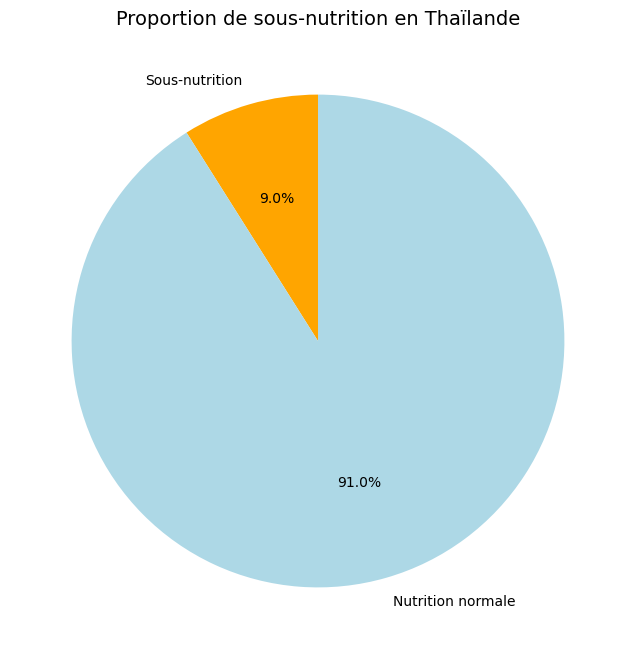

In [ ]:
#Calcul de la sous nutrition en Thaïlande
#faire jointure avec population 
sous_nutrition_thailande = proportion_sous_nutrition_2017[proportion_sous_nutrition_2017['Zone']=='Thaïlande']
#sous_nutrition_thailande

# Extraire les données nécessaires A VOIR ABSOLUMENT CAR DONNES PEUT ETRE INCOHERENTE
population_totale = sous_nutrition_thailande['Population'].values[0]
personnes_sous_nutrition = sous_nutrition_thailande['sous_nutrition'].values[0]
autres = population_totale - personnes_sous_nutrition

# Préparer les données pour le graphique
data = [personnes_sous_nutrition, autres]
labels = ['Sous-nutrition', 'Nutrition normale']

# Créer le graphique circulaire
plt.figure(figsize=(8, 8))
plt.pie(data, labels=labels, autopct='%1.1f%%', colors=['orange', 'lightblue'], startangle=90)

# Ajouter un titre
plt.title("Proportion de sous-nutrition en Thaïlande", fontsize=14)

# Afficher le graphique
plt.show()

In [ ]:
# On calcule la proportion exportée en fonction de la proportion
#préciser Manioc 

data_thailande_manioc = data_thailande[data_thailande['Produit']=='Manioc'].copy()#utilisation de copy() afin de ne pas appliquer les modifications sur la vue et ainsi éviter les confusions sur les effets de modifications
data_thailande_manioc['Proportion exportée (%)'] = (data_thailande_manioc['Exportations - Quantité (kg)']/data_thailande_manioc['Production (kg)'])*100
data_thailande_manioc['Proportion exportée (%)'] = data_thailande_manioc['Proportion exportée (%)'].fillna(0)

data_thailande_manioc[['Zone','Année','Disponibilité alimentaire en quantité (kg/personne/an)','Exportations - Quantité (kg)','Importations - Quantité (kg)','Proportion exportée (%)','Disponibilité alimentaire (Kcal/jour)']]


,Zone,Année,Disponibilité alimentaire en quantité (kg/personne/an),Exportations - Quantité (kg),Importations - Quantité (kg),Proportion exportée (%),Disponibilité alimentaire (Kcal/jour)
14166,Thaïlande,2017,13,"25,214,000,000,000","1,250,000,000,000",83,"2,768,392,400"


<div style="background-color: RGB(0,150,250);" >
<h2 style="margin: auto; padding: 20px; color:#fff; ">Etape 6 - Analyse complémentaires</h2>
</div>

In [ ]:
#Rajouter en dessous toutes les analyses complémtaires suite à la demande de mélanie :
#"et toutes les infos que tu trouverais utiles pour mettre en relief les pays qui semblent être 
#le plus en difficulté au niveau alimentaire"

# combien je devrai exporté en moins pour nourrir tout le monde

# On calcule la disponibilité alimentaire nécessaire par pays pour couvrir les besoins de la population
#Dispo_population_2017['Nourriture nécessaire (kg)'] = Dispo_population_2017['Population'] * 2.5 * 365

# On calcule le déficit alimentaire par pays (quantité manquante pour éviter la sous-nutrition)
#Dispo_population_2017['Déficit alimentaire (kg)'] = Dispo_population_2017['Nourriture nécessaire (kg)'] - Dispo_population_2017['Disponibilité intérieure (kg)']

# Si le déficit est supérieur à 0, il faudra réduire les exportations pour combler le manque
#Dispo_population_2017['Quantité à réduire des exportations (kg)'] = Dispo_population_2017['Déficit alimentaire (kg)'].apply(lambda x: x if x > 0 else 0)

#reduction = ['Zone', 'Produit', 'Disponibilité intérieure (kg)', 
   #                     'Exportations - Quantité (kg)', 
        #                'Population', 'Quantité à réduire des exportations (kg)']

#Dispo_population_2017_reduit = Dispo_population_2017[reduction]
#Dispo_population_2017_reduit.sort_values(by='Quantité à réduire des exportations (kg)',ascending=False).reset_index(drop=True)


# Filtrer les données pour la Thaïlande
dispo_thailande = Dispo_population_2017[Dispo_population_2017['Zone'] == 'Thaïlande']

# Calcul de la nourriture nécessaire pour la Thaïlande
dispo_thailande['Nourriture nécessaire (kg)'] = dispo_thailande['Population'] * 2.5 * 365

# Calcul du déficit alimentaire pour la Thaïlande
dispo_thailande['Déficit alimentaire (kg)'] = dispo_thailande['Nourriture nécessaire (kg)'] - dispo_thailande['Disponibilité intérieure (kg)']

# Calcul de la quantité à réduire des exportations sans utiliser lambda
dispo_thailande['Quantité à réduire des exportations (kg)'] = dispo_thailande['Déficit alimentaire (kg)']
dispo_thailande.loc[dispo_thailande['Déficit alimentaire (kg)'] < 0, 'Quantité à réduire des exportations (kg)'] = 0

# Affichage des résultats
dispo_thailande_reduit = dispo_thailande[['Zone', 'Produit', 'Disponibilité intérieure (kg)', 
                                           'Exportations - Quantité (kg)', 'Population', 
                                           'Quantité à réduire des exportations (kg)']]

# Trier les résultats par la quantité à réduire des exportations, en ordre décroissant
dispo_thailande_reduit.sort_values(by='Quantité à réduire des exportations (kg)', ascending=False).reset_index(drop=True)

# Afficher le résultat

C:\Users\jorda\AppData\Local\Temp\ipykernel_1536\3270226031.py:28: SettingWithCopyWarning: 
A value is trying to be set on a copy of a slice from a DataFrame.
Try using .loc[row_indexer,col_indexer] = value instead

See the caveats in the documentation: https://pandas.pydata.org/pandas-docs/stable/user_guide/indexing.html#returning-a-view-versus-a-copy
  dispo_thailande['Nourriture nécessaire (kg)'] = dispo_thailande['Population'] * 2.5 * 365
C:\Users\jorda\AppData\Local\Temp\ipykernel_1536\3270226031.py:31: SettingWithCopyWarning: 
A value is trying to be set on a copy of a slice from a DataFrame.
Try using .loc[row_indexer,col_indexer] = value instead

See the caveats in the documentation: https://pandas.pydata.org/pandas-docs/stable/user_guide/indexing.html#returning-a-view-versus-a-copy
  dispo_thailande['Déficit alimentaire (kg)'] = dispo_thailande['Nourriture nécessaire (kg)'] - dispo_thailande['Disponibilité intérieure (kg)']
C:\Users\jorda\AppData\Local\Temp\ipykernel_1536\3270

,Zone,Produit,Disponibilité intérieure (kg),Exportations - Quantité (kg),Population,Quantité à réduire des exportations (kg)
0,Thaïlande,"Viande, Autre","-92,000,000,000","96,000,000,000","69,209,810","155,153,951,625"
1,Thaïlande,Girofles,0,0,"69,209,810","63,153,951,625"
2,Thaïlande,"Sucre, betterave",0,0,"69,209,810","63,153,951,625"
3,Thaïlande,Ignames,0,0,"69,209,810","63,153,951,625"
4,Thaïlande,Huiles de Foie de Poisso,0,0,"69,209,810","63,153,951,625"
...,...,...,...,...,...,...
90,Thaïlande,Oeufs,"1,042,000,000,000","25,000,000,000","69,209,810",0
91,Thaïlande,Oignons,"98,000,000,000","41,000,000,000","69,209,810",0
92,Thaïlande,"Oranges, Mandarines","714,000,000,000","84,000,000,000","69,209,810",0
93,Thaïlande,Orge,"441,000,000,000",0,"69,209,810",0


In [ ]:

#Tentative d'analyse approffondie 


Dispo_population_2017_agrégé = Dispo_population_2017.groupby('Zone', as_index=False).agg({
    'Disponibilité intérieure (kg)': 'sum',
    'Exportations - Quantité (kg)': 'sum',
    'Population': 'sum'
})

# Calcul des besoins alimentaires
Dispo_population_2017_agrégé['Nourriture nécessaire (kg)'] = Dispo_population_2017_agrégé['Population'] * 2.5 * 365

# Calcul du déficit alimentaire
Dispo_population_2017_agrégé['Déficit alimentaire (kg)'] = (Dispo_population_2017_agrégé['Nourriture nécessaire (kg)'] - Dispo_population_2017_agrégé['Disponibilité intérieure (kg)']
)

# Calcul de la réduction des exportations nécessaire pour combler le déficit
Dispo_population_2017_agrégé['Quantité à réduire des exportations (kg)'] = Dispo_population_2017_agrégé['Déficit alimentaire (kg)'].apply(lambda x: x if x > 0 else 0)

# Trier les pays par déficit alimentaire
Dispo_population_2017_reduit = Dispo_population_2017_agrégé.sort_values(by='Quantité à réduire des exportations (kg)', ascending=True).reset_index(drop=True)

# Affichage du résultat
Dispo_population_2017_reduit_non_zero = Dispo_population_2017_reduit[Dispo_population_2017_reduit['Quantité à réduire des exportations (kg)'] > 0]

Dispo_population_2017_reduit_non_zero[['Zone', 'Disponibilité intérieure (kg)', 'Exportations - Quantité (kg)', 
                              'Population', 'Quantité à réduire des exportations (kg)']]


#Erreur


,Zone,Disponibilité intérieure (kg),Exportations - Quantité (kg),Population,Quantité à réduire des exportations (kg)


C:\Users\jorda\AppData\Local\Temp\ipykernel_1536\2398675479.py:3: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.barplot(data=pires_pays.head(10), x='Zone', y='proportion par pays (%)', palette='viridis')


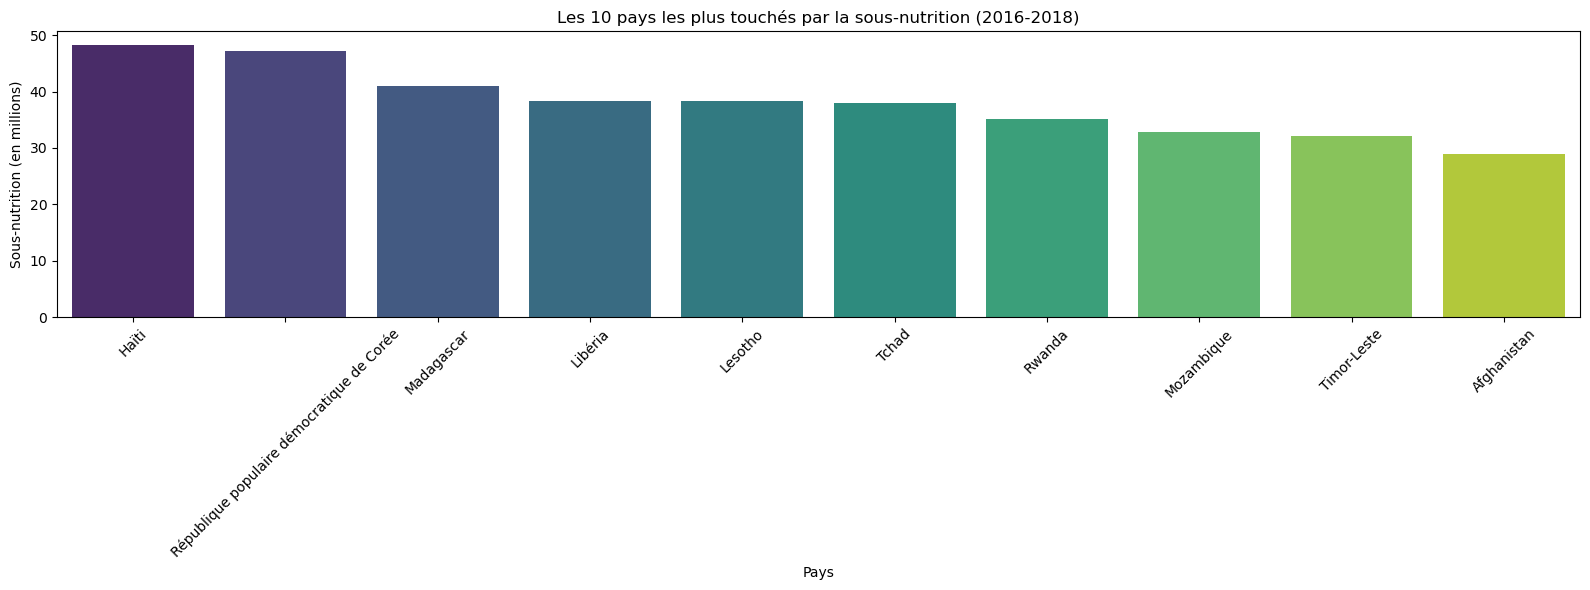

In [ ]:
# Création graphique 1
plt.figure(figsize=(16, 6))
sns.barplot(data=pires_pays.head(10), x='Zone', y='proportion par pays (%)', palette='viridis')

plt.title("Les 10 pays les plus touchés par la sous-nutrition (2016-2018)")
plt.xlabel("Pays")
plt.ylabel("Sous-nutrition (en millions)")
plt.xticks(rotation=45)  # Rotation des labels pour plus de lisibilité
plt.tight_layout()

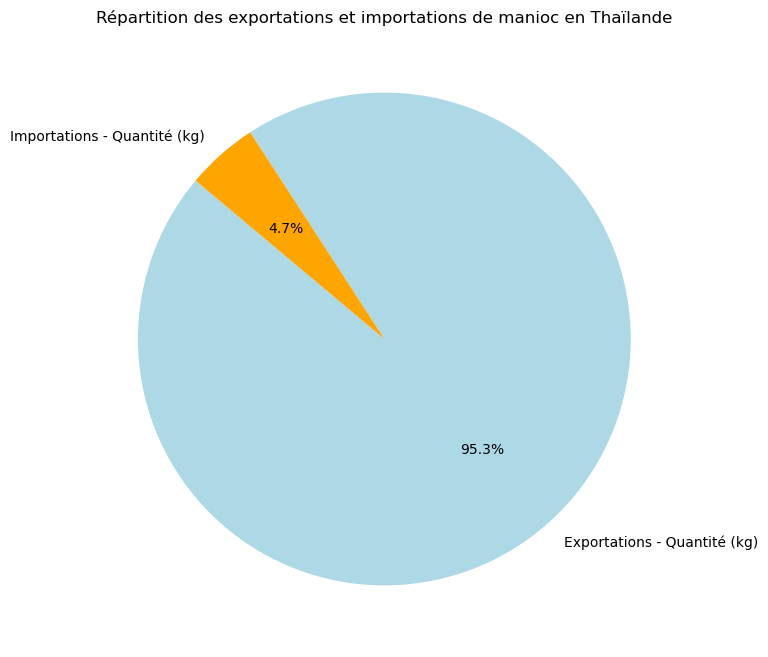

In [ ]:
#Création Graphique 2

# Sélection des valeurs pour le diagramme en secteurs
categories = ['Exportations - Quantité (kg)', 'Importations - Quantité (kg)']
valeurs = data_thailande_manioc[categories].sum()  # Somme pour chaque catégorie

# Création du diagramme
plt.figure(figsize=(8, 8))
plt.pie(valeurs, labels=categories, autopct='%1.1f%%', startangle=140, colors=['lightblue', 'orange'])
plt.title('Répartition des exportations et importations de manioc en Thaïlande')
plt.show()

C:\Users\jorda\AppData\Local\Temp\ipykernel_1536\1091219172.py:8: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.barplot(data=dispo_thailande_reduit_exportes, x='Produit', y='Quantité à réduire des exportations (kg)', palette='viridis')


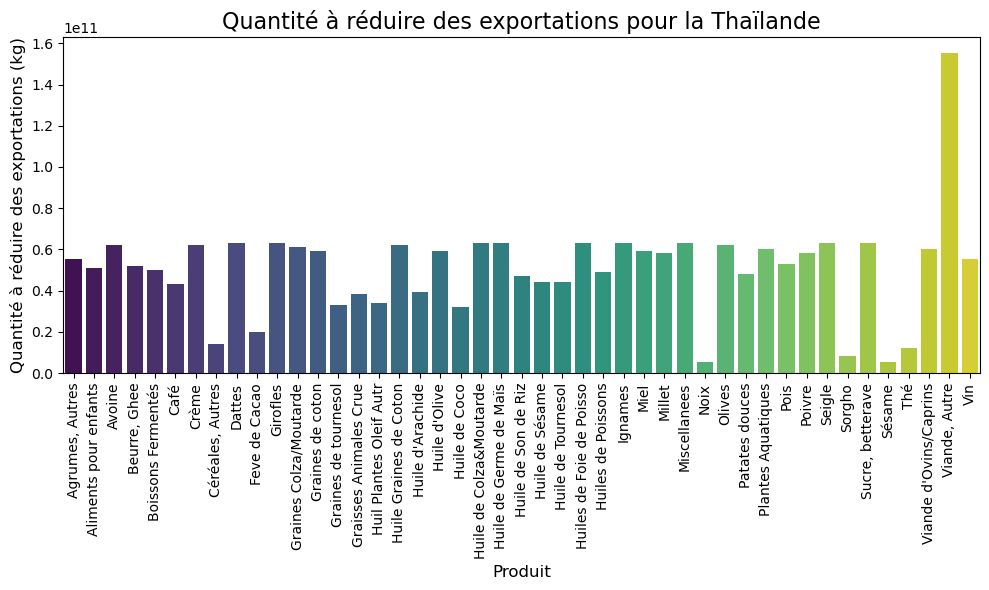

In [ ]:
#Création Graphique 3

# Filtrer pour ne garder que les produits où la quantité à réduire des exportations est supérieure à 0
dispo_thailande_reduit_exportes = dispo_thailande_reduit[dispo_thailande_reduit['Quantité à réduire des exportations (kg)'] > 0]

# Créer un graphique en barre pour la quantité à réduire des exportations
plt.figure(figsize=(10, 6))

# Tracer les barres en fonction de 'Produit' et 'Quantité à réduire des exportations (kg)'
sns.barplot(data=dispo_thailande_reduit_exportes, x='Produit', y='Quantité à réduire des exportations (kg)', palette='viridis')

# Ajouter un titre et des labels aux axes
plt.title('Quantité à réduire des exportations pour la Thaïlande', fontsize=16)
plt.xlabel('Produit', fontsize=12)
plt.ylabel('Quantité à réduire des exportations (kg)', fontsize=12)

# Faire tourner les labels des produits sur l’axe des X pour une meilleure lisibilité
plt.xticks(rotation=90)

# Afficher le graphique
plt.tight_layout()
plt.show()